In [1]:
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

X_train, y_train, X_test, y_test = joblib.load("../data/processed/data_processed.joblib")
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part d'attaques - train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Train : (175341, 60) | Test : (82332, 60)
Part d'attaques - train : 0.681 | test : 0.551


In [2]:
resultats = []  
os.makedirs("../docs/figures", exist_ok=True)


def evaluer(nom, modele, duree_entrainement=None):
    """Évalue un modèle sur le jeu de test et ajoute une ligne au tableau comparatif."""
    pred = modele.predict(X_test)
    if hasattr(modele, "predict_proba"):
        score = modele.predict_proba(X_test)[:, 1]
    elif hasattr(modele, "decision_function"):
        score = modele.decision_function(X_test)
    else:
        score = pred

    ligne = {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    if duree_entrainement is not None:
        ligne["Temps (s)"] = round(duree_entrainement, 1)

    resultats[:] = [r for r in resultats if r["Modèle"] != nom]  # évite les doublons si on relance
    resultats.append(ligne)
    return pred, score


def afficher_matrice(nom, pred):
    """Dessine et enregistre la matrice de confusion."""
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Normal", "Attaque"], cmap="Blues"
    )
    plt.title(f"Matrice de confusion - {nom}")
    plt.savefig(f"../docs/figures/matrice_{nom.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
Zero-R    0.5506     0.5506     1.0 0.7102      0.5        0.6


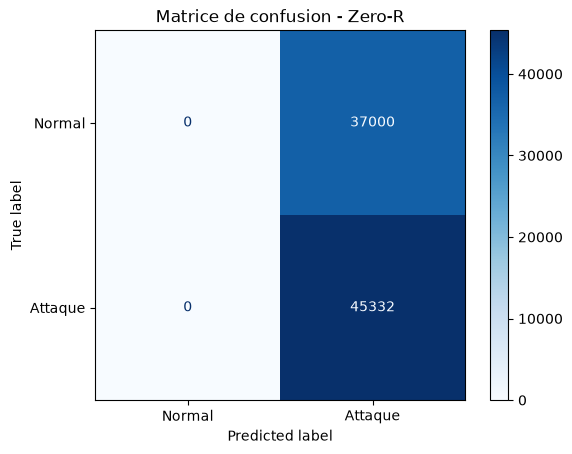

In [3]:
from sklearn.dummy import DummyClassifier

debut = time.time()
zero_r = DummyClassifier(strategy="most_frequent")
zero_r.fit(X_train, y_train)
pred, score = evaluer("Zero-R", zero_r, time.time() - debut)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
afficher_matrice("Zero-R", pred)